# Vodafone UK Coverage Gap: Stage 3 Spatial Modelling (1 km grid)



## 0. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install rasterio libpysal esda shap
import os, sys
from pathlib import Path
OUT = Path('/content/drive/MyDrive/vodafone-project/data'); FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
RAW = Path('/content/raw3'); RAW.mkdir(exist_ok=True)

Mounted at /content/drive


In [2]:
%%writefile /content/stage3_lib.py
"""
Stage 3 helpers: grid features (terrain, population, coast), spatial stats, spatial-CV models.

Grid = 1 km British National Grid cells (gx, gy = floor(easting/1000), floor(northing/1000)),
the same cells built in Stage 1.
"""
from __future__ import annotations

import math
from pathlib import Path

import numpy as np
import pandas as pd
import requests

GRID_M = 1000

# ------------------------------------------------------------------ helpers
def _to_grid(lon, lat):
    from pyproj import Transformer
    tf = Transformer.from_crs(4326, 27700, always_xy=True)
    x, y = tf.transform(lon, lat)
    return (np.floor(x / GRID_M)).astype("int64"), (np.floor(y / GRID_M)).astype("int64")


def cell_centroids_lonlat(gx, gy):
    from pyproj import Transformer
    tf = Transformer.from_crs(27700, 4326, always_xy=True)
    return tf.transform((np.asarray(gx) + .5) * GRID_M, (np.asarray(gy) + .5) * GRID_M)


def fetch(url, dest: Path, timeout=120):
    """Download once; return path, or None on 404 (e.g. all-sea DEM tile)."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    if dest.with_suffix(".missing").exists():
        return None
    r = requests.get(url, timeout=timeout, stream=True)
    if r.status_code in (403, 404):
        dest.with_suffix(".missing").touch()
        return None
    r.raise_for_status()
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(".part")
    with open(tmp, "wb") as f:
        for b in r.iter_content(1 << 20):
            f.write(b)
    tmp.rename(dest)
    return dest


def _raster_pixels(path, block=512):
    """Yield (lon, lat, value) arrays for a north-up lat/lon GeoTIFF, in row blocks."""
    import rasterio
    with rasterio.open(path) as src:
        T, nod, H, W = src.transform, src.nodata, src.height, src.width
        lon_c = T.c + (np.arange(W) + .5) * T.a
        for r0 in range(0, H, block):
            r1 = min(H, r0 + block)
            a = src.read(1, window=rasterio.windows.Window(0, r0, W, r1 - r0)).astype("float64")
            lat_c = T.f + (np.arange(r0, r1) + .5) * T.e
            lon, lat = np.meshgrid(lon_c, lat_c)
            v = a.ravel(); ok = np.isfinite(v)
            if nod is not None and np.isfinite(nod):
                ok &= v != nod
            yield lon.ravel()[ok], lat.ravel()[ok], v[ok]


DEM_URL = "https://copernicus-dem-90m.s3.amazonaws.com/Copernicus_DSM_COG_30_{ns}{lat:02d}_00_{ew}{lon:03d}_00_DEM/Copernicus_DSM_COG_30_{ns}{lat:02d}_00_{ew}{lon:03d}_00_DEM.tif"


def dem_tiles_for(gx, gy, buffer_km=5):
    """1°x1° tiles (lower-left lat, lon) needed to cover the cells + buffer."""
    tiles = set()
    for dx in (-buffer_km, 0, buffer_km):
        for dy in (-buffer_km, 0, buffer_km):
            lon, lat = cell_centroids_lonlat(np.asarray(gx) + dx, np.asarray(gy) + dy)
            tiles |= set(zip(np.floor(lat).astype(int), np.floor(lon).astype(int)))
    return sorted(tiles)


def dem_url(lat, lon):
    return DEM_URL.format(ns="N" if lat >= 0 else "S", lat=abs(lat), ew="E" if lon >= 0 else "W", lon=abs(lon))


def terrain_grid(tile_paths) -> pd.DataFrame:
    """Per 1 km cell: mean, std (ruggedness), min, max elevation from all tiles."""
    acc = []
    for p in tile_paths:
        for lon, lat, v in _raster_pixels(p):
            gx, gy = _to_grid(lon, lat)
            d = pd.DataFrame({"gx": gx, "gy": gy, "v": v, "v2": v * v})
            acc.append(d.groupby(["gx", "gy"]).agg(n=("v", "size"), s=("v", "sum"), s2=("v2", "sum"),
                                                     mn=("v", "min"), mx=("v", "max")).reset_index())
    t = pd.concat(acc).groupby(["gx", "gy"]).agg(n=("n", "sum"), s=("s", "sum"), s2=("s2", "sum"),
                                                  mn=("mn", "min"), mx=("mx", "max")).reset_index()
    t["elev_mean"] = t.s / t.n
    t["elev_std"] = np.sqrt(np.maximum(t.s2 / t.n - t.elev_mean ** 2, 0))
    t["elev_range"] = t.mx - t.mn
    t["elev_max"] = t.mx
    return t[["gx", "gy", "elev_mean", "elev_std", "elev_range", "elev_max"]]


WORLDPOP_URLS = [
    "https://data.worldpop.org/GIS/Population/Global_2000_2020_1km/2020/GBR/gbr_ppp_2020_1km_Aggregated.tif",
    "https://data.worldpop.org/GIS/Population/Global_2000_2020_Constrained/2020/BSGM/GBR/gbr_ppp_2020_constrained.tif",
]


def population_grid(path) -> pd.DataFrame:
    acc = []
    for lon, lat, v in _raster_pixels(path):
        v = np.where(v < 0, 0, v)
        gx, gy = _to_grid(lon, lat)
        acc.append(pd.DataFrame({"gx": gx, "gy": gy, "pop": v}).groupby(["gx", "gy"], as_index=False)["pop"].sum())
    return pd.concat(acc).groupby(["gx", "gy"], as_index=False)["pop"].sum()


def neighbourhood(df: pd.DataFrame, col: str, radius: int, how="mean") -> pd.Series:
    """Aggregate `col` over the (2r+1)^2 window around each cell.
    how='sum'  : sum (missing cells count as 0)      e.g. population within ~5 km
    how='mean' : mean of the cells that exist (ignores sea / missing cells)"""
    from scipy.ndimage import uniform_filter
    x0, y0 = df.gx.min() - radius, df.gy.min() - radius
    W, H = df.gx.max() - x0 + radius + 1, df.gy.max() - y0 + radius + 1
    iy, ix = (df.gy - y0).to_numpy(), (df.gx - x0).to_numpy()
    A = np.zeros((H, W)); P = np.zeros((H, W))
    v = df[col].to_numpy(dtype=float); ok = np.isfinite(v)
    A[iy[ok], ix[ok]] = v[ok]; P[iy[ok], ix[ok]] = 1
    k = (2 * radius + 1) ** 2
    S = uniform_filter(A, size=2 * radius + 1, mode="constant") * k
    if how == "sum":
        return pd.Series(S[iy, ix], index=df.index)
    C = uniform_filter(P, size=2 * radius + 1, mode="constant") * k
    return pd.Series(S[iy, ix] / np.maximum(C[iy, ix], 1e-9), index=df.index)


def coast_distance_km(gx, gy, lad) -> np.ndarray:
    import geopandas as gpd
    land = lad.to_crs(27700).geometry.union_all() if hasattr(lad.geometry, "union_all") else lad.to_crs(27700).unary_union
    coast = land.boundary
    pts = gpd.GeoSeries(gpd.points_from_xy((np.asarray(gx) + .5) * GRID_M, (np.asarray(gy) + .5) * GRID_M), crs=27700)
    return pts.distance(coast).to_numpy() / 1000


def morans_i(df, col, k=8, permutations=999, seed=0):
    from libpysal.weights import KNN
    from esda.moran import Moran
    W = KNN.from_array(np.c_[df.gx, df.gy], k=k); W.transform = "r"
    np.random.seed(seed)
    m = Moran(df[col].to_numpy(), W, permutations=permutations)
    return m, W


def lisa_clusters(df, col, W, permutations=999, alpha=0.05, seed=0):
    from esda.moran import Moran_Local
    np.random.seed(seed)
    lm = Moran_Local(df[col].to_numpy(), W, permutations=permutations)
    lab = np.array(["Not significant"] * len(df), dtype=object)
    sig = lm.p_sim < alpha
    names = {1: "High-High (hotspot)", 2: "Low-High", 3: "Low-Low (coldspot)", 4: "High-Low"}
    for q, nm in names.items():
        lab[sig & (lm.q == q)] = nm
    return pd.Series(lab, index=df.index), lm

def spatial_blocks(gx, gy, block_km=50):
    return (np.asarray(gx) // block_km).astype(int) * 10_000 + (np.asarray(gy) // block_km).astype(int)


def cv_evaluate(model_factory, X, y, groups=None, n_splits=5, seed=0, weight=None):
    """Out-of-fold predictions + metrics. groups=None -> random KFold (for comparison)."""
    from sklearn.model_selection import GroupKFold, KFold
    from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
    oof = np.full(len(y), np.nan)
    if groups is None:
        splits = KFold(n_splits, shuffle=True, random_state=seed).split(X)
    else:
        splits = GroupKFold(n_splits).split(X, y, groups)
    fold_r2 = []
    for tr, te in splits:
        m = model_factory()
        if weight is not None:
            m.fit(X.iloc[tr], y.iloc[tr], sample_weight=weight.iloc[tr])
        else:
            m.fit(X.iloc[tr], y.iloc[tr])
        oof[te] = m.predict(X.iloc[te])
        fold_r2.append(r2_score(y.iloc[te], oof[te]))
    return {"R2": r2_score(y, oof), "MAE": mean_absolute_error(y, oof),
            "RMSE": math.sqrt(mean_squared_error(y, oof)), "R2_fold_sd": float(np.std(fold_r2))}, oof


Writing /content/stage3_lib.py


In [3]:
sys.path.insert(0, '/content')
import importlib, stage3_lib as s3; importlib.reload(s3)
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
OPC = {'Vodafone': '#2a78d6', 'EE': '#eb6834', 'O2': '#1baf7a'}
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': SURF,
    'axes.facecolor': SURF, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.axisbelow': True})
def save(fig, name): fig.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight'); plt.show()

wide = pd.read_parquet(OUT / 'grid_gap_1km.parquet')
lad = gpd.read_file(OUT / 'lad_dec2024_uk.geojson')
master = pd.read_csv(OUT / 'la_master_stage1.csv')
print(wide.shape); wide.head(2)

(12626, 31)


,gx,gy,lad_cd,lad_nm,cov_in_share_EE,cov_in_share_O2,cov_in_share_Three,cov_in_share_Vodafone,cov_out_share_EE,cov_out_share_O2,cov_out_share_Three,cov_out_share_Vodafone,n_EE,n_O2,n_Three,n_Vodafone,rsrp_mean_EE,rsrp_mean_O2,rsrp_mean_Three,rsrp_mean_Vodafone,best_rival_cov_out_share,vo_gap_cov_out_share,cov_out_share_VodafoneThree,best_rival_cov_in_share,vo_gap_cov_in_share,cov_in_share_VodafoneThree,best_rival_rsrp_mean,vo_gap_rsrp_mean,rsrp_mean_VodafoneThree,vo_notspot_out,vo_notspot_in
0,125,846,S12000017,Highland,1.0,0.756184,0.0,0.833922,1.0,1.000000,0.0,1.000000,566.0,566.0,566.0,566.0,-71.612792,-91.082862,NaN,-90.880813,1.0,0.000000,1.000000,1.0,0.166078,0.833922,-71.612792,19.268021,-90.880813,0.000000,0.166078
1,125,847,S12000017,Highland,1.0,0.397335,0.0,0.355799,1.0,0.866771,0.0,0.865204,2552.0,2552.0,2552.0,2552.0,-64.082398,-96.514326,-131.984571,-97.370274,1.0,0.134796,0.865204,1.0,0.644201,0.355799,-64.082398,33.287876,-97.370274,0.134796,0.644201


## 1. Targets

In [4]:
g = wide.copy()
g['gx'] = g.gx.astype(int); g['gy'] = g.gy.astype(int)
g['gap_vs_EE'] = g.cov_in_share_EE - g.cov_in_share_Vodafone      # >0 = Vodafone behind EE
g['gap_vs_O2'] = g.cov_in_share_O2 - g.cov_in_share_Vodafone
g['vo_notspot'] = 1 - g.cov_in_share_Vodafone
g['n_meas'] = g.n_Vodafone
print(f'{len(g):,} cells')
display(g[['gap_vs_EE', 'gap_vs_O2', 'vo_notspot', 'n_meas']].describe().round(3))
print('Share of cells where Vodafone trails EE by >20 pts:', (g.gap_vs_EE > .2).mean().round(3))
print('Share of cells where Vodafone indoor coverage < 50% (weak):', (g.cov_in_share_Vodafone < .5).mean().round(3))

12,626 cells


,gap_vs_EE,gap_vs_O2,vo_notspot,n_meas
count,12626.000,12626.000,12626.000,12626.000
mean,0.057,-0.018,0.241,872.161
std,0.328,0.136,0.326,1509.389
min,-1.000,-1.000,0.000,20.000
25%,-0.038,-0.032,0.000,258.000
50%,0.000,0.000,0.067,478.000
75%,0.144,0.008,0.381,954.000
max,1.000,1.000,1.000,37837.000


Share of cells where Vodafone trails EE by >20 pts: 0.212
Share of cells where Vodafone indoor coverage < 50% (weak): 0.204


## 2. Terrain features (Copernicus GLO-90 DEM)


In [5]:
TERR_FILE = OUT / 'terrain_1km.parquet'
if TERR_FILE.exists():
    terr = pd.read_parquet(TERR_FILE)
else:
    tiles = s3.dem_tiles_for(g.gx, g.gy, buffer_km=6)
    print(len(tiles), 'candidate tiles')
    paths = []
    for i, (la, lo) in enumerate(tiles):
        p = s3.fetch(s3.dem_url(la, lo), RAW / f'dem_{la}_{lo}.tif')
        if p: paths.append(p)
        if i % 10 == 0: print(f'  {i+1}/{len(tiles)} checked, {len(paths)} on land')
    terr = s3.terrain_grid(paths)
    terr.to_parquet(TERR_FILE)
print(terr.shape); terr.describe().round(1)

43 candidate tiles
  1/43 checked, 1 on land
  11/43 checked, 11 on land
  21/43 checked, 21 on land
  31/43 checked, 31 on land
  41/43 checked, 41 on land
(311081, 6)


,gx,gy,elev_mean,elev_std,elev_range,elev_max
count,311081.0,311081.0,311081.0,311081.0,311081.0,311081.0
mean,336.9,500.8,114.0,13.8,55.4,143.8
std,114.4,284.0,153.3,20.5,79.0,185.3
min,88.0,11.0,-4.8,0.0,0.0,-2.2
25%,253.0,255.0,0.0,0.0,0.0,0.0
50%,333.0,487.0,56.6,6.3,27.8,80.0
75%,416.0,756.0,167.4,18.6,76.6,212.6
max,605.0,1019.0,1196.4,238.4,869.8,1341.3


## 3. Population (WorldPop 2020, 1 km)

In [6]:
POP_FILE = OUT / 'population_1km.parquet'
if POP_FILE.exists():
    popg = pd.read_parquet(POP_FILE)
else:
    p = None
    for u in s3.WORLDPOP_URLS:
        p = s3.fetch(u, RAW / u.split('/')[-1], timeout=600)
        if p: print('using', u); break
    assert p, 'WorldPop download failed: download gbr_ppp_2020_1km_Aggregated.tif from hub.worldpop.org and upload it to ' + str(RAW)
    popg = s3.population_grid(p)
    popg.to_parquet(POP_FILE)
print(f"{len(popg):,} cells, UK total ≈ {popg['pop'].sum()/1e6:.1f} M people")

using https://data.worldpop.org/GIS/Population/Global_2000_2020_1km/2020/GBR/gbr_ppp_2020_1km_Aggregated.tif
253,934 cells, UK total ≈ 67.6 M people


## 4. Feature table

In [7]:

full = terr.merge(popg, on=['gx', 'gy'], how='outer')
full['pop'] = full['pop'].fillna(0)
full['pop_5km']    = s3.neighbourhood(full, 'pop', 2, how='sum')        # 5x5 km window
full['pop_11km']   = s3.neighbourhood(full, 'pop', 5, how='sum')
full['rugged_5km'] = s3.neighbourhood(full, 'elev_std', 2)
full['rugged_11km']= s3.neighbourhood(full, 'elev_std', 5)
full['elev_rel']   = full.elev_mean - s3.neighbourhood(full, 'elev_mean', 3)

X = g.merge(full, on=['gx', 'gy'], how='left')
X['coast_km'] = s3.coast_distance_km(X.gx, X.gy, lad)
dens = master.assign(la_prem_density=master.prem_count / master.area_km2)[['lad_cd', 'la_prem_density']]
X = X.merge(dens, on='lad_cd', how='left')
X['log_pop'] = np.log1p(X['pop']); X['log_pop_5km'] = np.log1p(X.pop_5km); X['log_pop_11km'] = np.log1p(X.pop_11km)
X['log_la_density'] = np.log10(X.la_prem_density)
X['log_n_meas'] = np.log10(X.n_meas)
X['scotland'] = X.lad_cd.str.startswith('S').astype(int); X['wales'] = X.lad_cd.str.startswith('W').astype(int)

FEATS = ['elev_mean', 'elev_std', 'elev_range', 'elev_rel', 'rugged_5km', 'rugged_11km',
         'log_pop', 'log_pop_5km', 'log_pop_11km', 'coast_km', 'log_la_density', 'log_n_meas', 'scotland', 'wales']
print('Missing values per feature:'); print(X[FEATS].isna().sum()[lambda s: s > 0])
X = X.dropna(subset=FEATS + ['gap_vs_EE', 'vo_notspot']).reset_index(drop=True)
X.to_parquet(OUT / 'grid_features_1km.parquet')
print(f'{len(X):,} modelling cells')
X[FEATS].describe().T.round(2)[['mean', 'std', 'min', 'max']]

Missing values per feature:
Series([], dtype: int64)
12,626 modelling cells


,mean,std,min,max
elev_mean,93.59,77.74,-4.77,800.98
elev_std,14.56,16.75,0.00,238.38
elev_range,58.82,61.31,0.00,869.77
elev_rel,-17.96,45.03,-403.93,159.73
rugged_5km,15.23,14.38,0.42,134.30
rugged_11km,15.82,14.43,0.53,110.51
log_pop,4.36,2.40,0.00,9.98
log_pop_5km,8.04,2.38,1.20,12.25
log_pop_11km,9.71,2.26,2.96,13.44
coast_km,20.17,20.89,0.00,89.99


In [8]:

from scipy import stats
corr = pd.DataFrame({t: {f: stats.spearmanr(X[f], X[t]).statistic for f in FEATS} for t in ['vo_notspot', 'gap_vs_EE']}).round(3)
corr.sort_values('vo_notspot', key=abs, ascending=False)

,vo_notspot,gap_vs_EE
log_pop_5km,-0.240,-0.175
log_pop_11km,-0.218,-0.177
log_pop,-0.206,-0.158
log_la_density,-0.195,-0.167
elev_range,0.138,0.095
elev_std,0.136,0.093
rugged_11km,0.136,0.107
rugged_5km,0.135,0.110
scotland,0.085,0.080
elev_rel,-0.056,-0.042


## 5. Spatial autocorrelation


In [9]:
res = {}
for t in ['vo_notspot', 'gap_vs_EE']:
    m, W = s3.morans_i(X, t, k=8, permutations=999)
    res[t] = (m, W); print(f"{t:11s} Moran's I = {m.I:.3f}  (p = {m.p_sim:.3f}, expected under randomness ≈ {m.EI:.4f})")

/usr/local/lib/python3.13/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 11 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


vo_notspot  Moran's I = 0.442  (p = 0.001, expected under randomness ≈ -0.0001)
gap_vs_EE   Moran's I = 0.337  (p = 0.001, expected under randomness ≈ -0.0001)


,cells (gap vs EE),cells (not-spot)
lisa_gap,,
Not significant,9620,8101
High-High (hotspot),1207,1627
Low-Low (coldspot),1198,2319
Low-High,384,393
High-Low,217,186


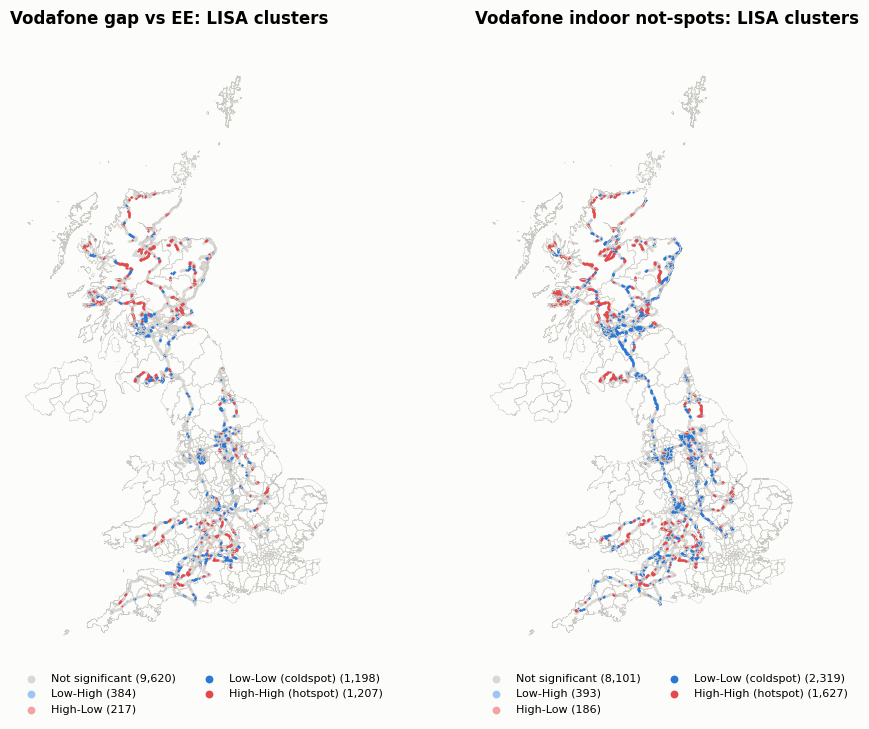

In [10]:
t = 'gap_vs_EE'
X['lisa_gap'], _ = s3.lisa_clusters(X, t, res[t][1], permutations=999)
X['lisa_notspot'], _ = s3.lisa_clusters(X, 'vo_notspot', res['vo_notspot'][1], permutations=999)
display(X.lisa_gap.value_counts().to_frame('cells (gap vs EE)').join(X.lisa_notspot.value_counts().to_frame('cells (not-spot)')))

cols = {'High-High (hotspot)': '#e34948', 'Low-Low (coldspot)': '#2a78d6', 'High-Low': '#f2a3a2', 'Low-High': '#9ec5f4', 'Not significant': '#d9d8d3'}
fig, axes = plt.subplots(1, 2, figsize=(11, 8))
lad27 = lad.to_crs(27700)
for ax, col, ttl in zip(axes, ['lisa_gap', 'lisa_notspot'], ['Vodafone gap vs EE: LISA clusters', 'Vodafone indoor not-spots: LISA clusters']):
    lad27.boundary.plot(ax=ax, color='#c9c8c2', lw=.3)
    for lab in ['Not significant', 'Low-High', 'High-Low', 'Low-Low (coldspot)', 'High-High (hotspot)']:
        s = X[X[col] == lab]
        ax.scatter((s.gx + .5) * 1000, (s.gy + .5) * 1000, s=2, color=cols[lab], label=f'{lab} ({len(s):,})', lw=0)
    ax.set_title(ttl); ax.set_aspect('equal'); ax.axis('off')
    ax.legend(loc='upper left', bbox_to_anchor=(0, 0), frameon=False, fontsize=8, markerscale=4, ncol=2)
save(fig, '05_lisa_maps')

In [11]:
# which LAs contain most gap hotspots?
hot = X[X.lisa_gap == 'High-High (hotspot)'].groupby('lad_nm').size().rename('hotspot_cells')
tot = X.groupby('lad_nm').size().rename('cells')
pd.concat([hot, tot], axis=1).dropna().assign(share=lambda d: d.hotspot_cells / d.cells).sort_values('hotspot_cells', ascending=False).head(15).round(2)

,hotspot_cells,cells,share
lad_nm,,,
Highland,306.0,1588,0.19
Argyll and Bute,110.0,436,0.25
Dumfries and Galloway,64.0,517,0.12
Fife,60.0,402,0.15
Aberdeenshire,55.0,528,0.10
Stirling,54.0,409,0.13
Somerset,50.0,399,0.13
Moray,37.0,163,0.23
Perth and Kinross,29.0,242,0.12


## 6. Models with spatial cross-validation


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor

blocks = s3.spatial_blocks(X.gx, X.gy, block_km=50)
print('spatial blocks:', len(np.unique(blocks)))
models = {
    'Baseline (mean)': lambda: DummyRegressor(),
    'Linear':          lambda: make_pipeline(StandardScaler(), LinearRegression()),
    'XGBoost':         lambda: XGBRegressor(n_estimators=600, max_depth=5, learning_rate=.04, subsample=.8,
                                            colsample_bytree=.8, min_child_weight=10, n_jobs=-1),
}
rows, OOF = [], {}
for target in ['vo_notspot', 'gap_vs_EE']:
    y = X[target]
    for name, f in models.items():
        r_sp, oof = s3.cv_evaluate(f, X[FEATS], y, groups=blocks)
        r_rd, _ = s3.cv_evaluate(f, X[FEATS], y, groups=None)
        OOF[(target, name)] = oof
        rows.append({'target': target, 'model': name, 'R2 spatial CV': r_sp['R2'], 'R2 random CV': r_rd['R2'],
                     'MAE spatial': r_sp['MAE'], 'R2 fold SD': r_sp['R2_fold_sd']})
results = pd.DataFrame(rows).round(3); results.to_csv(OUT / 'stage3_model_results.csv', index=False)
results

spatial blocks: 90


,target,model,R2 spatial CV,R2 random CV,MAE spatial,R2 fold SD
0,vo_notspot,Baseline (mean),-0.006,-0.000,0.266,0.018
1,vo_notspot,Linear,0.101,0.125,0.244,0.074
2,vo_notspot,XGBoost,0.071,0.252,0.241,0.093
3,gap_vs_EE,Baseline (mean),-0.003,-0.000,0.215,0.005
4,gap_vs_EE,Linear,0.018,0.032,0.214,0.025
5,gap_vs_EE,XGBoost,-0.046,0.137,0.226,0.056


## 7. Explaining the model (SHAP)

In [13]:
import shap
expl = {}
for target in ['vo_notspot', 'gap_vs_EE']:
    mdl = models['XGBoost']().fit(X[FEATS], X[target])
    sv = shap.TreeExplainer(mdl).shap_values(X[FEATS])
    expl[target] = (mdl, sv)
    imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False)
    print(f'\n{target}: mean |SHAP| (percentage points)'); print((imp * 100).round(2).to_string())


vo_notspot: mean |SHAP| (percentage points)
log_pop_5km       6.40
coast_km          3.20
elev_mean         2.93
log_la_density    2.45
log_n_meas        2.13
log_pop_11km      2.12
rugged_5km        2.06
elev_rel          2.00
rugged_11km       1.75
log_pop           1.67
elev_std          1.17
elev_range        0.95
scotland          0.45
wales             0.15

gap_vs_EE: mean |SHAP| (percentage points)
log_pop_11km      2.89
coast_km          2.69
log_la_density    2.54
rugged_5km        2.34
elev_mean         2.05
log_pop_5km       1.58
log_n_meas        1.51
rugged_11km       1.48
log_pop           1.40
elev_rel          1.39
elev_std          1.30
elev_range        1.22
wales             0.24
scotland          0.09


/tmp/ipykernel_1993/2622561916.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(expl[target][1], X[FEATS], show=False, max_display=10, plot_size=(8, 4.5))


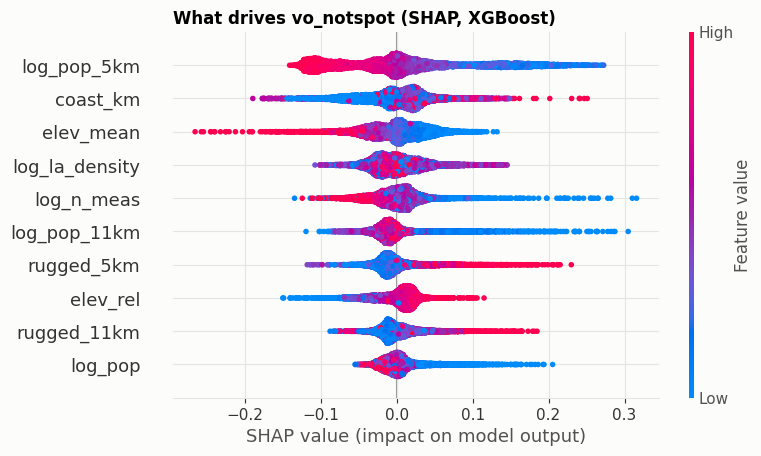

/tmp/ipykernel_1993/2622561916.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(expl[target][1], X[FEATS], show=False, max_display=10, plot_size=(8, 4.5))


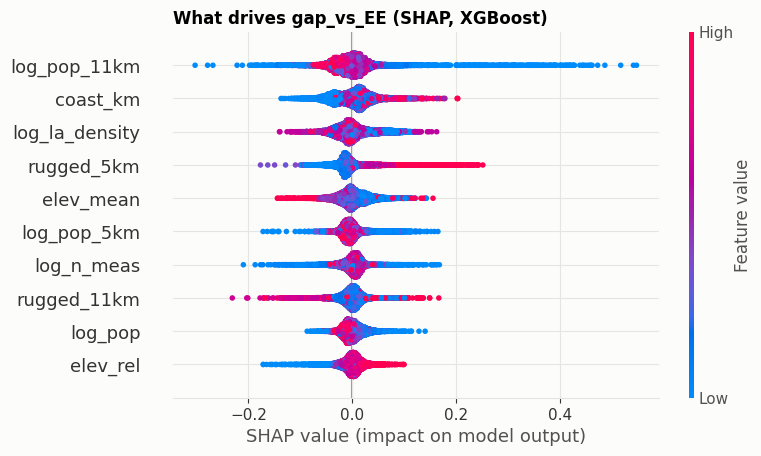

In [14]:
for target in ['vo_notspot', 'gap_vs_EE']:
    shap.summary_plot(expl[target][1], X[FEATS], show=False, max_display=10, plot_size=(8, 4.5))
    plt.title(f'What drives {target} (SHAP, XGBoost)', loc='left', fontweight='bold')
    save(plt.gcf(), f'06_shap_{target}')

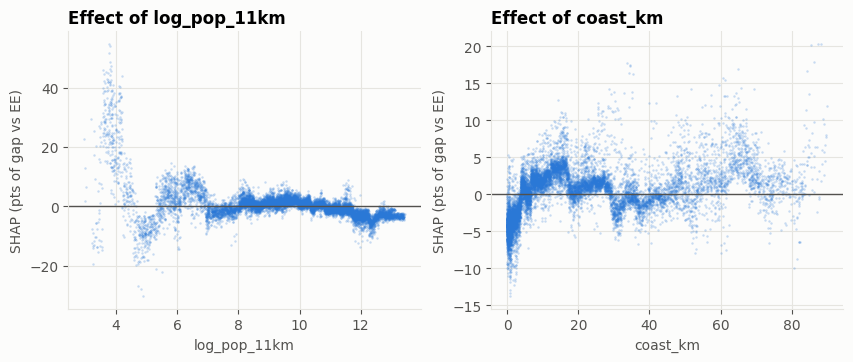

In [15]:

_, sv = expl['gap_vs_EE']
top2 = pd.Series(np.abs(sv).mean(0), index=FEATS).nlargest(2).index
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, f in zip(axes, top2):
    i = FEATS.index(f)
    ax.scatter(X[f], sv[:, i] * 100, s=3, alpha=.25, color=OPC['Vodafone'], lw=0)
    ax.axhline(0, color=INK2, lw=1); ax.set_xlabel(f); ax.set_ylabel('SHAP (pts of gap vs EE)')
    ax.set_title(f'Effect of {f}')
save(fig, '07_shap_dependence_gap')

## 8. Residual check


In [16]:
for target in ['vo_notspot', 'gap_vs_EE']:
    X[f'resid_{target}'] = X[target] - OOF[(target, 'XGBoost')]
    m, _ = s3.morans_i(X, f'resid_{target}', k=8, permutations=199)
    print(f"{target:11s} residual Moran's I = {m.I:.3f} (p = {m.p_sim:.3f})   vs raw target I = {res[target][0].I:.3f}")

/usr/local/lib/python3.13/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 11 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


vo_notspot  residual Moran's I = 0.365 (p = 0.005)   vs raw target I = 0.442


/usr/local/lib/python3.13/dist-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 11 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


gap_vs_EE   residual Moran's I = 0.329 (p = 0.005)   vs raw target I = 0.337


In [17]:
X.to_parquet(OUT / 'grid_model_stage3.parquet')
print('Saved:', OUT / 'grid_model_stage3.parquet', '|', OUT / 'stage3_model_results.csv', '| figures in', FIG)

Saved: /content/drive/MyDrive/vodafone-project/data/grid_model_stage3.parquet | /content/drive/MyDrive/vodafone-project/data/stage3_model_results.csv | figures in /content/drive/MyDrive/vodafone-project/data/figures
